# Manufacturing Supply Chain Analysis
## Step 2: Cross-Departmental Analysis (SQL)

The cleaned tables from Step 1 are loaded into an in-memory SQLite database so the three departments can be joined directly. Every finding below spans at least two of the three sheets.

In [1]:
import pandas as pd
import sqlite3
from pathlib import Path

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 40)

DATA = Path('.')
con = sqlite3.connect(':memory:')

purchase = pd.read_csv(DATA / 'clean_purchase.csv')
store    = pd.read_csv(DATA / 'clean_store_inventory.csv')
sales    = pd.read_csv(DATA / 'clean_sales.csv')

purchase.to_sql('purchase', con, index=False, if_exists='replace')
store.to_sql('store', con, index=False, if_exists='replace')
sales.to_sql('sales', con, index=False, if_exists='replace')

def q(sql):
    """Run a query and return the result as a DataFrame."""
    return pd.read_sql(sql, con)

print("Loaded:", q("SELECT COUNT(*) AS purchase_rows FROM purchase").iloc[0,0],
      q("SELECT COUNT(*) AS store_rows FROM store").iloc[0,0],
      q("SELECT COUNT(*) AS sales_rows FROM sales").iloc[0,0])

Loaded: 131 1201 401


## Finding 1: One vendor's late deliveries caused 53 late customer orders

This traces across all three sheets:
Purchase (vendor delays) -> Store (raw material stockout) -> Sales (late orders)

In [2]:
q1 = q("""
SELECT Vendor_Name,
       COUNT(*)                                AS po_lines,
       ROUND(AVG(Promised_Lead_Time_Days),1)   AS avg_promised_days,
       ROUND(AVG(Actual_Lead_Time_Days),1)     AS avg_actual_days,
       ROUND(AVG(Lead_Time_Slip_Days),1)       AS avg_slip_days,
       MAX(Lead_Time_Slip_Days)                AS worst_slip_days
FROM purchase
WHERE Is_Open_PO = 0
GROUP BY Vendor_Name
ORDER BY avg_slip_days DESC
""")
print(q1.to_string(index=False))

              Vendor_Name  po_lines  avg_promised_days  avg_actual_days  avg_slip_days  worst_slip_days
    Coastal Steel Traders        23               11.3             15.7            4.4             27.0
     Central Ferro Alloys        24               11.3             12.3            1.0              3.0
   Plateau Alloys Pvt Ltd        33               11.3             11.9            0.6              3.0
     Eastline Metal Works        29               11.3             11.9            0.6              3.0
   Hilltop Scrap & Metals         8               11.8             12.1            0.4              3.0
Meridian Ferro Industries         7               15.7             16.0            0.3              3.0


In [3]:
q2 = q("""
SELECT PO_ID, PO_Date, Vendor_Name, Material_Name, Quantity_Kg,
       Promised_Lead_Time_Days, Actual_Lead_Time_Days, Lead_Time_Slip_Days,
       Actual_Delivery_Date
FROM purchase
WHERE Lead_Time_Slip_Days > 7
ORDER BY PO_Date
""")
from IPython.display import display
display(q2)
print(f"Total quantity delayed: {q2.Quantity_Kg.sum():,} kg")

,PO_ID,PO_Date,Vendor_Name,Material_Name,Quantity_Kg,Promised_Lead_Time_Days,Actual_Lead_Time_Days,Lead_Time_Slip_Days,Actual_Delivery_Date
0,PO-0022,2026-02-24,Coastal Steel Traders,MS Plates,1963,13,35.0,22.0,2026-03-31
1,PO-0006,2026-02-25,Coastal Steel Traders,Steel Scrap,2227,11,37.0,26.0,2026-04-03
2,PO-0023,2026-03-05,Coastal Steel Traders,MS Plates,895,9,34.0,25.0,2026-04-08
3,PO-0024,2026-03-18,Coastal Steel Traders,MS Plates,1167,11,38.0,27.0,2026-04-25


Total quantity delayed: 6,252 kg


In [4]:
q3 = q("""
SELECT s.month, s.Item_Name, s.received_kg, s.issued_kg, c.closing_kg
FROM (
    SELECT substr(Txn_Date,1,7) AS month, Item_Code, Item_Name,
           SUM(CASE WHEN Movement_Type='Inward-Purchase'      THEN Quantity ELSE 0 END) AS received_kg,
           SUM(CASE WHEN Movement_Type='Issued-to-Production' THEN Quantity ELSE 0 END) AS issued_kg
    FROM store
    WHERE Item_Code IN ('RM-SS','RM-MS')
    GROUP BY month, Item_Code
) s
JOIN (
    SELECT month, Item_Code, Balance_After_Txn AS closing_kg FROM (
        SELECT substr(Txn_Date,1,7) AS month, Item_Code, Balance_After_Txn,
               ROW_NUMBER() OVER (PARTITION BY Item_Code, substr(Txn_Date,1,7)
                                  ORDER BY Txn_Date DESC, Txn_ID DESC) AS rn
        FROM store WHERE Item_Code IN ('RM-SS','RM-MS')
    ) WHERE rn = 1
) c ON c.month = s.month AND c.Item_Code = s.Item_Code
ORDER BY s.Item_Name, s.month
""")
print(q3.to_string(index=False))

  month   Item_Name  received_kg  issued_kg  closing_kg
2026-01   MS Plates         2199       3580         757
2026-02   MS Plates         4292       3380        1669
2026-03   MS Plates         1963       1669        1963
2026-04   MS Plates         6057       3554        4466
2026-05   MS Plates         2157       4022        2601
2026-06   MS Plates         3675       3675        2601
2026-01 Steel Scrap         5780       7290        2439
2026-02 Steel Scrap         6450       6304        2585
2026-03 Steel Scrap         2233       4494         324
2026-04 Steel Scrap         9656       5903        4077
2026-05 Steel Scrap         5720       7192        2605
2026-06 Steel Scrap         6542       7787        1360


In [5]:
from IPython.display import display, Markdown

q4 = q("""
SELECT substr(Order_Date,1,7)         AS month,
       COUNT(*)                       AS delayed_orders,
       ROUND(AVG(Days_Late),1)        AS avg_days_late,
       ROUND(SUM(Total_Value_INR),0)  AS value_inr
FROM sales
WHERE Order_Status = 'Delayed'
GROUP BY month
ORDER BY month
""")

q4b = q("""
SELECT Product_Name,
       COUNT(*)                       AS delayed_orders,
       ROUND(AVG(Days_Late),1)        AS avg_days_late,
       ROUND(SUM(Total_Value_INR),0)  AS value_inr
FROM sales
WHERE Order_Status = 'Delayed'
GROUP BY Product_Name
ORDER BY value_inr DESC
""")

totals = q("""
SELECT COUNT(*)                      AS orders,
       ROUND(SUM(Total_Value_INR),0) AS value_inr,
       COUNT(DISTINCT Customer_Name) AS customers,
       ROUND(AVG(Days_Late),1)       AS avg_days_late
FROM sales WHERE Order_Status = 'Delayed'
""")

display(Markdown("**Delayed orders by month**"))
display(q4.style.format({'value_inr': '{:,.0f}'}).hide(axis='index'))

display(Markdown("**Delayed orders by product**"))
display(q4b.style.format({'value_inr': '{:,.0f}'}).hide(axis='index'))

display(Markdown("**Total impact**"))
display(totals.style.format({'value_inr': '{:,.0f}'}).hide(axis='index'))

**Delayed orders by month**

month,delayed_orders,avg_days_late,value_inr
2026-02,16,21.100000,"1,715,878"
2026-03,37,22.300000,"4,189,316"


**Delayed orders by product**

Product_Name,delayed_orders,avg_days_late,value_inr
Crusher Liner,12,23.600000,"1,607,840"
Mill Liner - Standard,10,22.800000,"1,602,060"
Hammer - Standard,13,20.300000,"1,064,977"
Mill Liner - Heavy Duty,7,17.600000,"829,179"
Shredder Hammer,5,21.400000,"422,933"
Wear Plate,6,26.000000,"378,204"


**Total impact**

orders,value_inr,customers,avg_days_late
53,"5,905,194",12,21.900000


In [6]:
q5 = q("""
SELECT Material_Name, Vendor_Name,
       COUNT(*) AS po_count,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY Material_Name), 1) AS pct_of_material
FROM purchase
WHERE Material_Code IN ('RM-MS','RM-SS')
GROUP BY Material_Name, Vendor_Name
ORDER BY Material_Name, po_count DESC
""")
print(q5.to_string(index=False))

Material_Name            Vendor_Name  po_count  pct_of_material
    MS Plates  Coastal Steel Traders        17            100.0
  Steel Scrap  Coastal Steel Traders         8             50.0
  Steel Scrap Hilltop Scrap & Metals         8             50.0


## Finding 2: Sugar demand fell 93% but purchasing of sugar-line raw
## materials continued

Sales (season ends) -> Store (consumption collapses) -> Purchase (buying continues)

In [7]:
q6 = q("""
SELECT substr(Order_Date,1,7)       AS month,
       COUNT(*)                     AS sugar_orders,
       ROUND(SUM(Total_Value_INR),0) AS value_inr
FROM sales
WHERE Customer_Industry = 'Sugar'
GROUP BY month
ORDER BY month
""")
print(q6.to_string(index=False))

first, last = q6.value_inr.iloc[0], q6.value_inr.iloc[-1]
print(f"\nJan to Jun: Rs {first:,.0f} -> Rs {last:,.0f}  ({(last-first)/first*100:.0f}%)")

  month  sugar_orders  value_inr
2026-01            31  2518964.0
2026-02            21  1903822.0
2026-03            21  1816005.0
2026-04             7   541399.0
2026-05             1    50970.0
2026-06             3   168986.0

Jan to Jun: Rs 2,518,964 -> Rs 168,986  (-93%)


In [8]:
q7 = q("""
SELECT substr(Txn_Date,1,7) AS month, SUM(Quantity) AS sugar_units_produced
FROM store
WHERE Movement_Type = 'Finished Goods-In'
  AND Item_Code IN ('SKU-GR01','SKU-GR02','SKU-SR01','SKU-BS01')
GROUP BY month
ORDER BY month
""")
print(q7.to_string(index=False))

  month  sugar_units_produced
2026-01                   218
2026-02                   349
2026-03                   303
2026-04                    64
2026-05                    43
2026-06                    38


In [9]:
display(q("""
SELECT Product_Name, Customer_Industry, COUNT(*) AS orders
FROM sales
WHERE Product_SKU IN ('SKU-GR01','SKU-GR02','SKU-SR01','SKU-BS01')
GROUP BY Product_Name, Customer_Industry
ORDER BY Product_Name
"""))

,Product_Name,Customer_Industry,orders
0,Bush & Bearing Sleeve,Sugar,15
1,Grinding Roller - Heavy Duty,Sugar,26
2,Grinding Roller - Standard,Sugar,20
3,Mill Roller Shaft,Sugar,23


In [10]:
from IPython.display import display, Markdown

q8 = q("""
SELECT s.month, s.Item_Name, s.received_kg, s.issued_kg, c.closing_kg
FROM (
    SELECT substr(Txn_Date,1,7) AS month, Item_Code, Item_Name,
           SUM(CASE WHEN Movement_Type='Inward-Purchase'      THEN Quantity ELSE 0 END) AS received_kg,
           SUM(CASE WHEN Movement_Type='Issued-to-Production' THEN Quantity ELSE 0 END) AS issued_kg
    FROM store WHERE Item_Code IN ('RM-PI','RM-FM')
    GROUP BY month, Item_Code
) s
JOIN (
    SELECT month, Item_Code, Balance_After_Txn AS closing_kg FROM (
        SELECT substr(Txn_Date,1,7) AS month, Item_Code, Balance_After_Txn,
               ROW_NUMBER() OVER (PARTITION BY Item_Code, substr(Txn_Date,1,7)
                                  ORDER BY Txn_Date DESC, Txn_ID DESC) AS rn
        FROM store WHERE Item_Code IN ('RM-PI','RM-FM')
    ) WHERE rn = 1
) c ON c.month = s.month AND c.Item_Code = s.Item_Code
ORDER BY s.Item_Name, s.month
""")

for material in ['Pig Iron', 'Ferro Manganese']:
    t = (q8[q8.Item_Name == material]
         .rename(columns={'month':'Month', 'received_kg':'Received (kg)',
                          'issued_kg':'Issued to production (kg)', 'closing_kg':'Closing stock (kg)'})
         [['Month','Issued to production (kg)','Received (kg)','Closing stock (kg)']])

    opening, closing = t['Closing stock (kg)'].iloc[0], t['Closing stock (kg)'].iloc[-1]

    display(Markdown(f"**{material}** — closing stock {opening:,} kg → {closing:,} kg "
                     f"(**{(closing-opening)/opening*100:+.0f}%**)"))
    display(t.style.format({'Issued to production (kg)':'{:,.0f}',
                            'Received (kg)':'{:,.0f}',
                            'Closing stock (kg)':'{:,.0f}'}).hide(axis='index'))

**Pig Iron** — closing stock 1,484 kg → 12,973 kg (**+774%**)

Month,Issued to production (kg),Received (kg),Closing stock (kg)
2026-01,"5,145","3,226","1,484"
2026-02,"4,736","4,028",776
2026-03,"6,035","6,113",854
2026-04,"1,713","3,938","3,079"
2026-05,"1,906","5,948","7,121"
2026-06,"2,085","7,937","12,973"


**Ferro Manganese** — closing stock 431 kg → 4,760 kg (**+1004%**)

Month,Issued to production (kg),Received (kg),Closing stock (kg)
2026-01,"1,752","1,081",431
2026-02,"1,508","1,554",477
2026-03,"1,684","1,765",558
2026-04,601,"2,098","1,991"
2026-05,593,"1,207","2,605"
2026-06,632,"2,787","4,760"


In [11]:
from IPython.display import display, Markdown

q9 = q("""
SELECT Material_Name                AS Material,
       COUNT(*)                     AS POs_placed,
       SUM(Quantity_Kg)             AS Kg_ordered,
       ROUND(SUM(Total_Cost_INR),0) AS Spend_INR
FROM purchase
WHERE Material_Code IN ('RM-PI','RM-FM') AND PO_Date >= '2026-04-01'
GROUP BY Material_Name
""")

q10 = q("""
SELECT c.Item_Name                               AS Material,
       c.closing_kg                              AS Closing_stock_kg,
       j.june_issue_kg                           AS June_consumption_kg,
       ROUND(1.0*c.closing_kg/j.june_issue_kg,1) AS Months_of_cover,
       ROUND(p.jun_rate,2)                       AS Rate_per_kg,
       ROUND(c.closing_kg*p.jun_rate,0)          AS Stock_value_INR
FROM (SELECT Item_Code, Item_Name, Balance_After_Txn AS closing_kg FROM (
        SELECT Item_Code, Item_Name, Balance_After_Txn,
               ROW_NUMBER() OVER (PARTITION BY Item_Code ORDER BY Txn_Date DESC, Txn_ID DESC) rn
        FROM store WHERE Item_Code IN ('RM-PI','RM-FM')) WHERE rn=1) c
JOIN (SELECT Item_Code, SUM(Quantity) AS june_issue_kg FROM store
      WHERE Movement_Type='Issued-to-Production' AND substr(Txn_Date,1,7)='2026-06'
        AND Item_Code IN ('RM-PI','RM-FM') GROUP BY Item_Code) j ON j.Item_Code=c.Item_Code
JOIN (SELECT Material_Code, AVG(Unit_Cost_INR_per_Kg) AS jun_rate FROM purchase
      WHERE substr(PO_Date,1,7)='2026-06' GROUP BY Material_Code) p ON p.Material_Code=c.Item_Code
ORDER BY Stock_value_INR DESC
""")

display(Markdown("**Purchased after sugar demand collapsed (Apr-Jun)**"))
display(q9.style.format({'Kg_ordered':'{:,.0f}', 'Spend_INR':'{:,.0f}'}).hide(axis='index'))

display(Markdown("**Stock position at 30 June**"))
display(q10.style.format({'Closing_stock_kg':'{:,.0f}', 'June_consumption_kg':'{:,.0f}',
                          'Months_of_cover':'{:.1f}', 'Rate_per_kg':'{:,.2f}',
                          'Stock_value_INR':'{:,.0f}'}).hide(axis='index'))

summary_line = (f"{q9.POs_placed.sum()} purchase orders covering {q9.Kg_ordered.sum():,.0f} kg "
                f"were placed after demand collapsed, at a cost of Rs {q9.Spend_INR.sum():,.0f}. "
                f"Rs {q10.Stock_value_INR.sum():,.0f} of working capital now sits in stock "
                f"with 6-8 months of cover against current consumption.")
display(Markdown(f"**{summary_line}**"))

**Purchased after sugar demand collapsed (Apr-Jun)**

Material,POs_placed,Kg_ordered,Spend_INR
Ferro Manganese,8,"6,136","544,298"
Pig Iron,9,"19,042","706,413"


**Stock position at 30 June**

Material,Closing_stock_kg,June_consumption_kg,Months_of_cover,Rate_per_kg,Stock_value_INR
Pig Iron,"12,973","2,085",6.2,36.85,"478,098"
Ferro Manganese,"4,760",632,7.5,87.82,"418,023"


**17 purchase orders covering 25,178 kg were placed after demand collapsed, at a cost of Rs 1,250,711. Rs 896,121 of working capital now sits in stock with 6-8 months of cover against current consumption.**

## Supporting observation: input cost rises reach the price list about two months late

Purchase (Ferro Chrome cost) -> Sales (Crusher Liner price)

In [12]:
q11 = q("""
SELECT f.month,
       ROUND(f.fc_rate,2)  AS ferro_chrome_per_kg,
       ROUND(c.cr_price,0) AS crusher_liner_price
FROM (SELECT substr(PO_Date,1,7) AS month, AVG(Unit_Cost_INR_per_Kg) AS fc_rate
      FROM purchase WHERE Material_Code='RM-FC' GROUP BY month) f
JOIN (SELECT substr(Order_Date,1,7) AS month, AVG(Unit_Price_INR) AS cr_price
      FROM sales WHERE Product_SKU='SKU-CR01' GROUP BY month) c ON c.month=f.month
ORDER BY f.month
""")
# Index both series to January = 100 so the timing of each rise is comparable
q11['fc_index'] = (100 * q11.ferro_chrome_per_kg / q11.ferro_chrome_per_kg.iloc[0]).round(1)
q11['cr_index'] = (100 * q11.crusher_liner_price / q11.crusher_liner_price.iloc[0]).round(1)
print(q11.to_string(index=False))

  month  ferro_chrome_per_kg  crusher_liner_price  fc_index  cr_index
2026-01               136.37               6997.0     100.0     100.0
2026-02               154.20               6963.0     113.1      99.5
2026-03               182.90               6969.0     134.1      99.6
2026-04               187.26               7412.0     137.3     105.9
2026-05               176.75               7529.0     129.6     107.6
2026-06               161.55               7673.0     118.5     109.7


In [13]:
with pd.ExcelWriter(DATA / 'sql_results.xlsx', engine='openpyxl') as xl:
    q1.to_excel(xl,  sheet_name='F1.1 Vendor performance', index=False)
    q2.to_excel(xl,  sheet_name='F1.2 Delayed POs', index=False)
    q3.to_excel(xl,  sheet_name='F1.3 Stock impact', index=False)
    q4b.to_excel(xl, sheet_name='F1.4 Delayed orders', index=False)
    q5.to_excel(xl,  sheet_name='F1.5 Sole source', index=False)
    q6.to_excel(xl,  sheet_name='F2.1 Sugar demand', index=False)
    q8.to_excel(xl,  sheet_name='F2.3 PI-FM stock', index=False)
    q10.to_excel(xl, sheet_name='F2.4 Capital tied up', index=False)
    q11.to_excel(xl, sheet_name='F3 Cost pass-through', index=False)

print("SQL results exported.")

SQL results exported.


## Charts

The two headline findings, plus the gap between reported and actual on-time delivery found in the data quality audit.

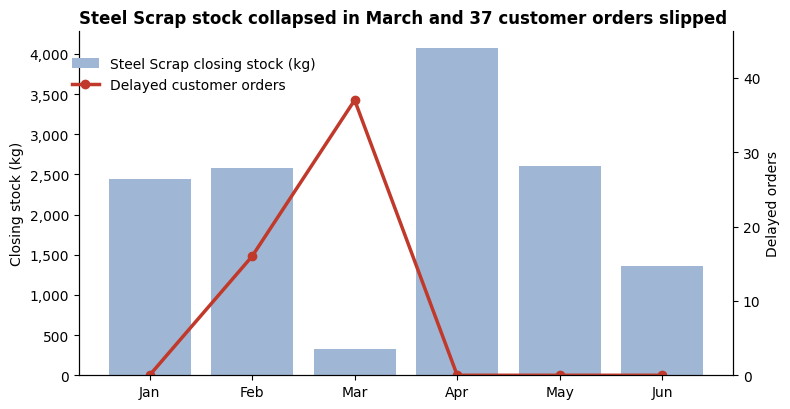

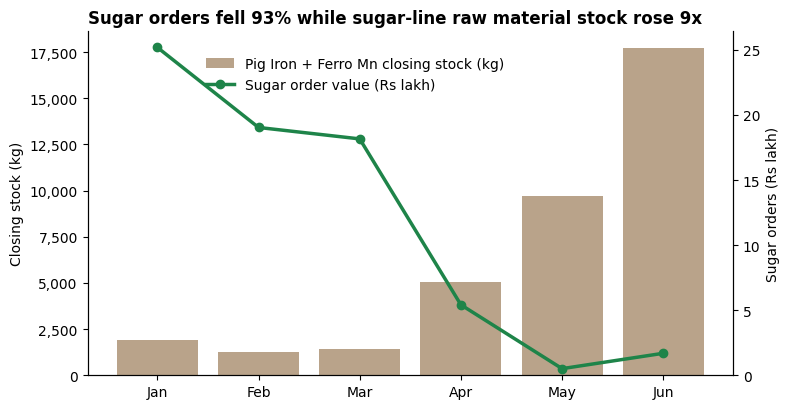

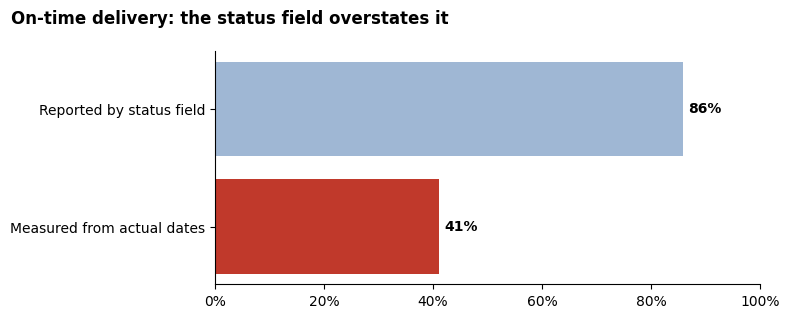

In [14]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

IMG = Path('.'); IMG.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False})
cd = pd.read_excel(DATA / 'chart_data.xlsx', sheet_name=None)
c1, c2 = cd['Chart1_Supply_Break'], cd['Chart2_Seasonal_Mismatch']
months = pd.to_datetime(c1.month).dt.strftime('%b')

# Chart 1 - supply break
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(months, c1.Steel_Scrap_Closing_Kg, color='#9fb7d4', label='Steel Scrap closing stock (kg)')
ax.set_ylabel('Closing stock (kg)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax2 = ax.twinx()
ax2.plot(months, c1.Delayed_Orders, color='#c0392b', marker='o', lw=2.5, label='Delayed customer orders')
ax2.set_ylabel('Delayed orders'); ax2.set_ylim(0, c1.Delayed_Orders.max() * 1.25)
ax2.spines['top'].set_visible(False)
ax.set_title('Steel Scrap stock collapsed in March and 37 customer orders slipped', loc='left', fontweight='bold')
fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.88), frameon=False)
fig.tight_layout(); fig.savefig(IMG / 'finding1_supply_break.png', dpi=160); plt.show()

# Chart 2 - seasonal mismatch
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(months, c2.PigIron_FerroMn_Closing_Kg, color='#b9a38a', label='Pig Iron + Ferro Mn closing stock (kg)')
ax.set_ylabel('Closing stock (kg)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax2 = ax.twinx()
ax2.plot(months, c2.Sugar_Order_Value_INR / 1e5, color='#1e8449', marker='o', lw=2.5, label='Sugar order value (Rs lakh)')
ax2.set_ylabel('Sugar orders (Rs lakh)'); ax2.set_ylim(0, None)
ax2.spines['top'].set_visible(False)
ax.set_title('Sugar orders fell 93% while sugar-line raw material stock rose 9x', loc='left', fontweight='bold')
fig.legend(loc='upper center', bbox_to_anchor=(0.45, 0.88), frameon=False)
fig.tight_layout(); fig.savefig(IMG / 'finding2_seasonal_mismatch.png', dpi=160); plt.show()

# Chart 3 - what the status field says vs what the dates say
otd = q("""
SELECT ROUND(100.0 * SUM(Order_Status <> 'Delayed') / COUNT(*), 1) AS by_status,
       ROUND(100.0 * SUM(Days_Late <= 0) / COUNT(*), 1)          AS by_dates
FROM sales WHERE Actual_Dispatch_Date IS NOT NULL
""").iloc[0]
fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(['Measured from actual dates', 'Reported by status field'], [otd.by_dates, otd.by_status],
               color=['#c0392b', '#9fb7d4'])
ax.bar_label(bars, labels=[f'{v:.0f}%' for v in [otd.by_dates, otd.by_status]], padding=4, fontweight='bold')
ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.spines['right'].set_visible(False)
fig.suptitle('On-time delivery: the status field overstates it', x=0.02, ha='left', fontweight='bold')
fig.tight_layout(); fig.savefig(IMG / 'on_time_delivery_gap.png', dpi=160); plt.show()

con.close()